In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

#Load dataset
df = pd.read_csv("../data/prescription_large.csv", encoding='ISO-8859-9')

In [5]:
#Basic Information
print("📏 Dataset shape (rows, columns):", df.shape)

print("\n🧾 Column names and data types:")
print(df.dtypes)

print("\n🔍 First 5 rows:")
display(df.head())

📏 Dataset shape (rows, columns): (10800, 7)

🧾 Column names and data types:
Yil                         int64
Ay                          int64
Recete Sayisi               int64
Ortalama Recete Bedeli    float64
Toplam Ilac Harcamasi     float64
Markali İlac Orani        float64
Saglik Enflasyonu         float64
dtype: object

🔍 First 5 rows:


,Yil,Ay,Recete Sayisi,Ortalama Recete Bedeli,Toplam Ilac Harcamasi,Markali İlac Orani,Saglik Enflasyonu
0,2015,1,2088161,136.83,285723069.6,0.60,0.08
1,2015,1,2714226,130.43,354016497.2,0.65,0.08
2,2015,1,1999049,154.72,309292861.3,0.47,0.08
3,2015,1,2396229,160.49,384570792.2,0.56,0.08
4,2015,1,1893024,104.66,198123891.8,0.62,0.08


In [6]:
#Missing values
print("🧩 Missing value count per column:")
display(df.isnull().sum())

print("\n📊 Missing value percentage:")
display((df.isnull().sum() / len(df) * 100).round(2).astype(str) + '%')

🧩 Missing value count per column:


Yil                       0
Ay                        0
Recete Sayisi             0
Ortalama Recete Bedeli    0
Toplam Ilac Harcamasi     0
Markali İlac Orani        0
Saglik Enflasyonu         0
dtype: int64


📊 Missing value percentage:


Yil                       0.0%
Ay                        0.0%
Recete Sayisi             0.0%
Ortalama Recete Bedeli    0.0%
Toplam Ilac Harcamasi     0.0%
Markali İlac Orani        0.0%
Saglik Enflasyonu         0.0%
dtype: object

In [7]:
#Descriptive statistics
print("📊 Descriptive statistics:")
display(df.describe().T)

📊 Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Yil,10800.0,2.019000e+03,2.582108e+00,2015.00,2.017000e+03,2.019000e+03,2.021000e+03,2.023000e+03
Ay,10800.0,6.500000e+00,3.452212e+00,1.00,3.750000e+00,6.500000e+00,9.250000e+00,1.200000e+01
Recete Sayisi,10800.0,1.998349e+06,3.656244e+05,666569.00,1.740902e+06,1.979536e+06,2.235178e+06,3.598568e+06
Ortalama Recete Bedeli,10800.0,1.388691e+02,2.825051e+01,43.61,1.195675e+02,1.376950e+02,1.571900e+02,2.602500e+02
Toplam Ilac Harcamasi,10800.0,2.796566e+08,8.470494e+07,52472311.68,2.177970e+08,2.701587e+08,3.312429e+08,6.919397e+08
Markali İlac Orani,10800.0,5.999259e-01,1.001469e-01,0.30,5.300000e-01,6.000000e-01,6.700000e-01,9.000000e-01
Saglik Enflasyonu,10800.0,1.600000e-01,4.944361e-02,0.08,1.200000e-01,1.700000e-01,1.900000e-01,2.400000e-01


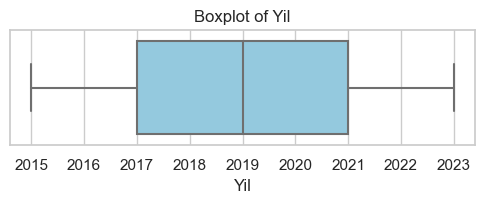

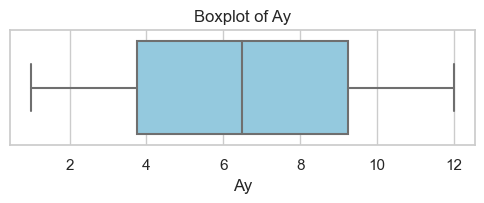

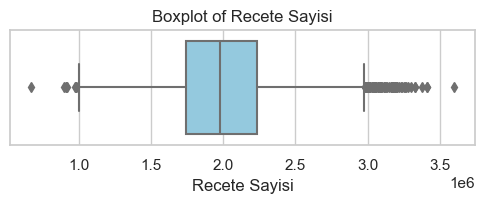

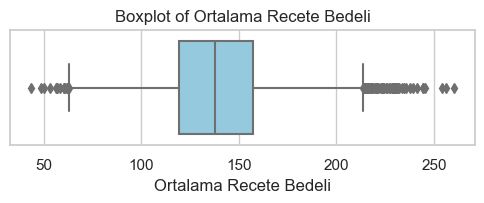

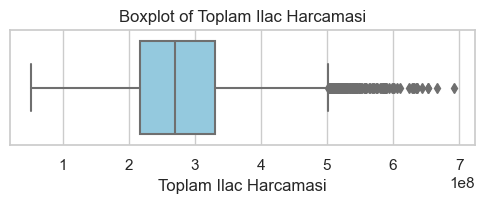

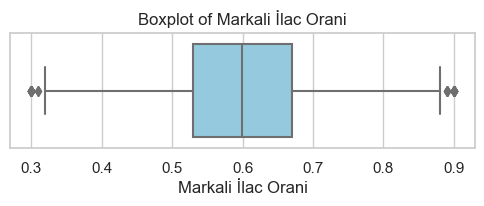

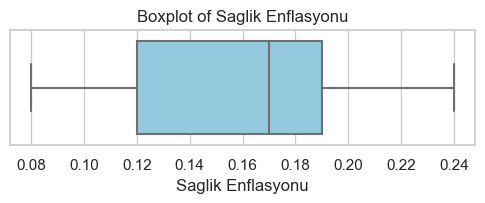

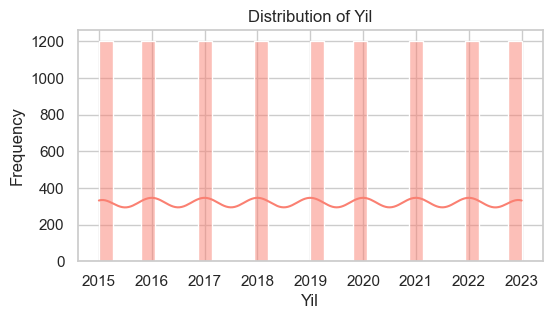

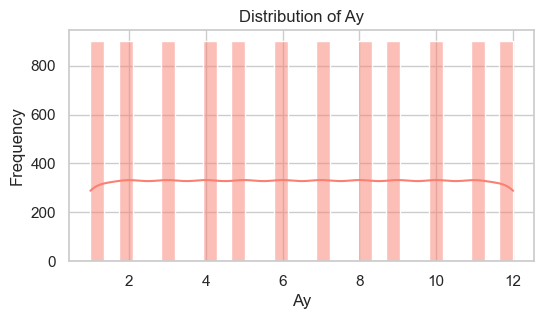

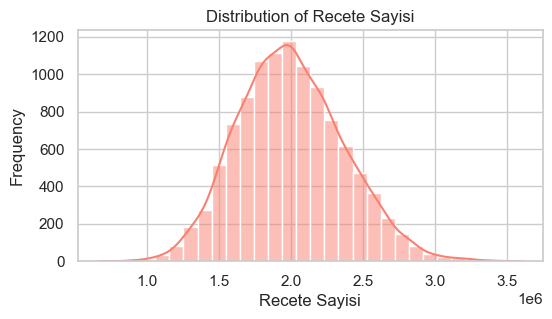

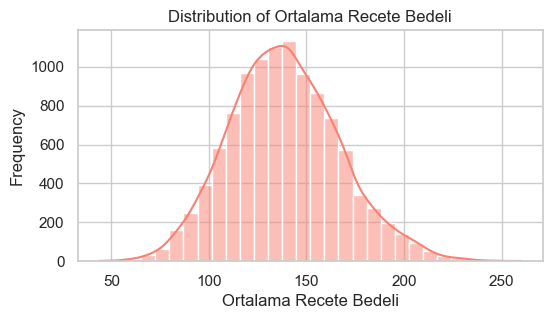

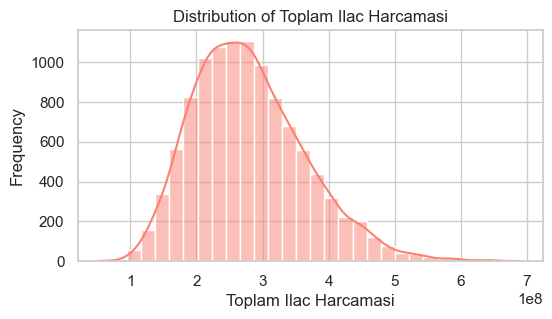

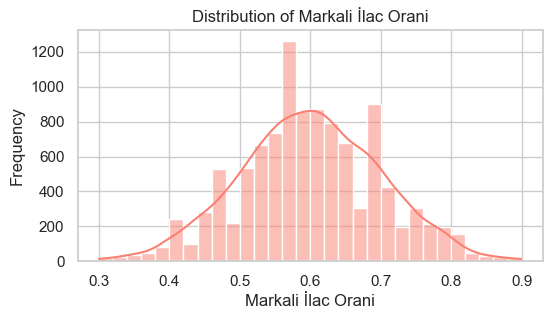

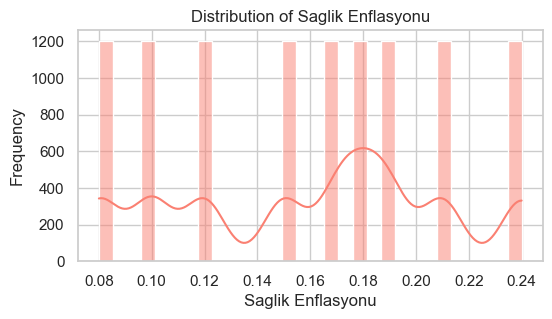

In [8]:
#Outlier detection and distribution for numerical columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

#Boxplots
for col in numeric_cols:
    plt.figure(figsize=(6, 1.5))
    sns.boxplot(x=df[col], color="skyblue")
    plt.title(f"Boxplot of {col}")
    plt.show()

#Histograms
for col in numeric_cols:
    plt.figure(figsize=(6, 3))
    sns.histplot(df[col], kde=True, bins=30, color="salmon")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

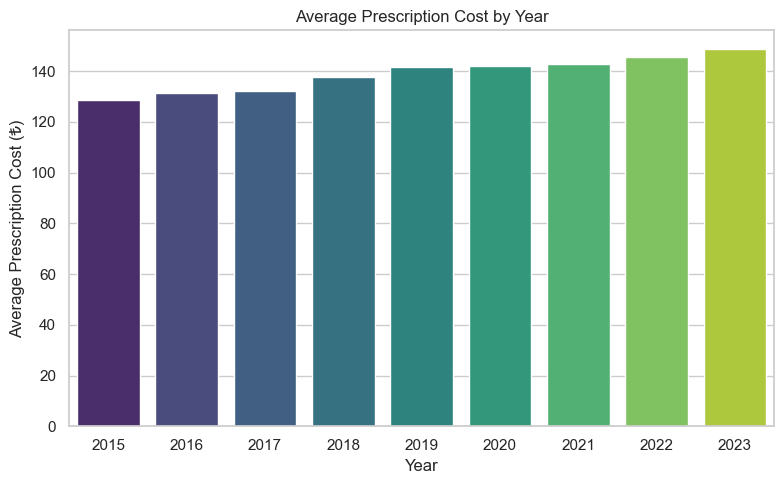

In [11]:
# Grouped barplot: Average Prescription Cost per Year
if 'Yil' in df.columns and 'Ortalama Recete Bedeli' in df.columns:
    avg_per_year = df.groupby('Yil')['Ortalama Recete Bedeli'].mean().sort_index()

    plt.figure(figsize=(8, 5))
    sns.barplot(x=avg_per_year.index, y=avg_per_year.values, palette="viridis")
    plt.title("Average Prescription Cost by Year")
    plt.xlabel("Year")
    plt.ylabel("Average Prescription Cost (₺)")
    plt.tight_layout()
    plt.show()

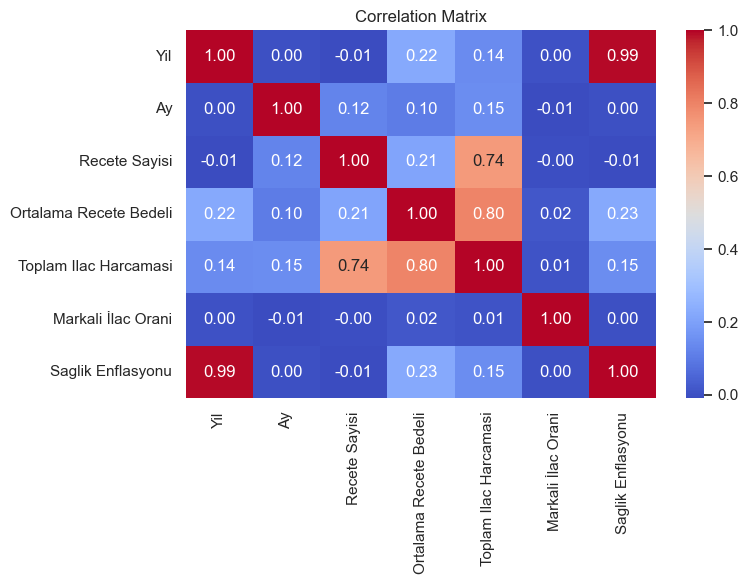

In [12]:
#Correlation matrix
if len(numeric_cols) > 1:
    plt.figure(figsize=(8, 6))
    corr = df[numeric_cols].corr()
    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
    plt.title("Correlation Matrix")
    plt.tight_layout()
    plt.show()